# BERT Experiment Analysis

## 1. Introduction

This notebook analyzes six completed `bert-base-uncased` experiments for binary answerability classification of mathematical word problems. Labels are `ANSWERABLE = 0` and `UNANSWERABLE = 1`; UNANSWERABLE is the positive class for precision, recall and F1. Models were trained on the fixed SUM training split and selected using SUM validation F1. The selected model has recorded evaluations on the held-out SUM test split and the external UMWP benchmark.

Only existing experiment artifacts are read. No training, model loading, inference or dataset preparation is performed. Run from the project root or `notebooks/` using **Run All**. Required analysis packages: pandas, matplotlib and Jupyter/IPython.

In [1]:
from pathlib import Path
import json
import math

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

PROJECT_ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "src/05_train_bert_run02.py").is_file()
     and (p / "results/bert").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Start from the CDS1092 project root or notebooks directory.")
BERT_RESULTS = PROJECT_ROOT / "results/bert"
LABELS = ["ANSWERABLE", "UNANSWERABLE"]
METRICS = ["eval_accuracy", "eval_precision", "eval_recall", "eval_f1"]
plt.rcParams.update({"font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False})


def read_json(path):
    with path.open(encoding="utf-8") as handle:
        return json.load(handle)


def load_run(directory):
    report = read_json(directory / "validation_metrics.json")
    history = pd.read_csv(directory / "training_history.csv")
    metadata = report["configuration"]
    config_path = directory / "config.json"
    if config_path.is_file():
        config = read_json(config_path)
        for key in config.keys() & metadata.keys():
            if config[key] != metadata[key]:
                raise ValueError(f"{directory.name}: conflicting configuration field {key}")
        config = {**metadata, **config}
        config_source = "config.json + validation_metrics.json"
    elif directory.name == "run_01":
        config = metadata.copy()
        config_source = "validation_metrics.json (no config.json)"
    else:
        raise FileNotFoundError(config_path)

    # Trainer logs its training summary before evaluate() is called again.
    # Separate events by that boundary, not by epoch: the restored model's
    # evaluation inherits the last training epoch in Trainer state.
    required = {"epoch", "step", "loss", "eval_loss", *METRICS, "train_runtime"}
    if not required.issubset(history.columns):
        raise ValueError(f"{directory.name}: missing history columns {required - set(history)}")
    summaries = history.index[history["train_runtime"].notna()]
    if len(summaries) != 1:
        raise ValueError(f"{directory.name}: expected exactly one training-summary event")
    boundary = summaries[0]
    epoch_events = history.loc[history.index < boundary]
    validation = epoch_events.loc[epoch_events["eval_f1"].notna()].copy()
    training = epoch_events.loc[epoch_events["loss"].notna()].copy()
    restored = history.loc[(history.index > boundary) & history["eval_f1"].notna()]
    if validation.empty or training.empty or len(restored) != 1:
        raise ValueError(f"{directory.name}: unexpected training/evaluation event structure")
    if validation["epoch"].duplicated().any() or training["epoch"].duplicated().any():
        raise ValueError(f"{directory.name}: ambiguous repeated epoch events")
    checkpoint_step = int(report["best_checkpoint"].replace("\\", "/").rsplit("checkpoint-", 1)[1])
    candidates = validation.loc[validation["step"].eq(checkpoint_step)]
    if len(candidates) != 1:
        raise ValueError(f"{directory.name}: best checkpoint has no unique epoch event")
    best = candidates.iloc[0]
    checkpoint_f1 = report["best_checkpoint_validation_f1"]
    if not math.isclose(best["eval_f1"], checkpoint_f1, abs_tol=1e-12, rel_tol=0):
        raise ValueError(f"{directory.name}: checkpoint F1 and epoch event disagree")
    if not math.isclose(validation["eval_f1"].max(), checkpoint_f1, abs_tol=1e-12, rel_tol=0):
        raise ValueError(f"{directory.name}: recorded checkpoint is not a maximum-F1 event")
    for metric in ["eval_loss", *METRICS]:
        if not math.isclose(restored.iloc[0][metric], report["best_validation_metrics"][metric],
                            abs_tol=1e-12, rel_tol=0):
            raise ValueError(f"{directory.name}: restored evaluation and JSON disagree")
    return {"config": config, "config_source": config_source, "report": report,
            "training": training, "validation": validation, "best": best,
            "restored": restored.iloc[0], "checkpoint_f1": checkpoint_f1}


run_directories = sorted(p for p in BERT_RESULTS.glob("run_*") if p.is_dir())
expected_runs = {f"run_{i:02d}" for i in range(1, 7)}
if {p.name for p in run_directories} != expected_runs:
    raise ValueError("Expected the six completed BERT runs, run_01 through run_06.")
runs = {p.name: load_run(p) for p in run_directories}
run_labels = {name: f"Run {int(name.split('_')[1]):02d}" for name in runs}
print(f"Loaded {len(runs)} BERT runs from {BERT_RESULTS.relative_to(PROJECT_ROOT)}")

Loaded 6 BERT runs from results\bert


## 2. Experiment Configuration

Each run is loaded from its saved configuration, validation report and training history. Run 01 has no separate `config.json`; its recorded `validation_metrics.json.configuration` is used explicitly. Best epoch is identified by matching the saved best-checkpoint step to the original epoch evaluation, not the post-training reevaluation. No missing settings are inferred from other runs.

In [2]:
configuration_rows = []
for name, run in runs.items():
    config = run["config"]
    configuration_rows.append({
        "Run": run_labels[name],
        "Learning rate": config["learning_rate"],
        "Maximum epochs": config["max_epochs"],
        "Best epoch": int(run["best"]["epoch"]),
        "Batch size": config["batch_size"],
        "Warmup steps": config["warmup_steps"],
    })
configuration_table = pd.DataFrame(configuration_rows).set_index("Run")
display(configuration_table.style.format({"Learning rate": "{:.0e}"}))

shared_keys = ["model_name", "max_length", "batch_size", "weight_decay", "warmup_ratio",
               "random_seed", "optimizer", "scheduler", "early_stopping_patience",
               "torch_version", "transformers_version"]
shared = {}
for key in shared_keys:
    values = [run["config"][key] for run in runs.values()]
    if any(value != values[0] for value in values):
        raise ValueError(f"Expected shared setting differs across runs: {key}")
    shared[key] = values[0]
display(Markdown(
    f"All runs use **{shared['model_name']}**, train/evaluation batch size "
    f"**{shared['batch_size']}**, maximum input length **{shared['max_length']}**, "
    f"weight decay **{shared['weight_decay']}**, warmup ratio **{shared['warmup_ratio']}**, "
    f"seed **{shared['random_seed']}**, **{shared['optimizer']}** and a "
    f"**{shared['scheduler']}** scheduler. The scripts use dynamic padding, gradient "
    "accumulation 1, data seed 42, epoch evaluation/saving/logging, and early stopping "
    f"patience **{shared['early_stopping_patience']}** (threshold 0). "
    "The checkpoint with the highest binary UNANSWERABLE F1 is restored; at most "
    "two checkpoints are retained. Warmup steps are rounded up from 5% of the "
    "planned optimizer steps, so changing the epoch budget also changes the LR schedule. "
    f"Reports record PyTorch **{shared['torch_version']}** and Transformers "
    f"**{shared['transformers_version']}**. "
    "Settings not recorded in the reports are described here only when explicit "
    "in `src/04_train_bert_run01.py` through the other run-specific training scripts."
))

,Learning rate,Maximum epochs,Best epoch,Batch size,Warmup steps
Run,,,,,
Run 01,2e-05,5,5,32,399
Run 02,3e-05,7,7,32,559
Run 03,2e-05,7,7,32,559
Run 04,4e-05,7,7,32,559
Run 05,5e-05,5,5,32,399
Run 06,5e-05,7,5,32,559


All runs use **bert-base-uncased**, train/evaluation batch size **32**, maximum input length **256**, weight decay **0.01**, warmup ratio **0.05**, seed **42**, **adamw_torch** and a **linear** scheduler. The scripts use dynamic padding, gradient accumulation 1, data seed 42, epoch evaluation/saving/logging, and early stopping patience **2** (threshold 0). The checkpoint with the highest binary UNANSWERABLE F1 is restored; at most two checkpoints are retained. Warmup steps are rounded up from 5% of the planned optimizer steps, so changing the epoch budget also changes the LR schedule. Reports record PyTorch **2.11.0+cu128** and Transformers **5.22.2**. Settings not recorded in the reports are described here only when explicit in `src/04_train_bert_run01.py` through the other run-specific training scripts.

## 3. Validation Results

The comparison uses each saved checkpoint's original epoch evaluation. Binary precision, recall and F1 refer to UNANSWERABLE, with argmax predictions and `zero_division=0`, as defined in the training scripts' `compute_metrics`. The recorded **best-checkpoint validation F1** is the selection criterion. The selected row is marked in bold.

In [3]:
selected_run = max(runs, key=lambda name: runs[name]["checkpoint_f1"])
validation_rows = []
for name, run in runs.items():
    best = run["best"]
    validation_rows.append({
        "Run": run_labels[name], "Best epoch": int(best["epoch"]),
        "Accuracy": best["eval_accuracy"],
        "Precision (UNANSWERABLE)": best["eval_precision"],
        "Recall (UNANSWERABLE)": best["eval_recall"],
        "F1 (UNANSWERABLE)": run["checkpoint_f1"],
    })
validation_table = pd.DataFrame(validation_rows).set_index("Run")
metric_columns = list(validation_table.columns[1:])
display(validation_table.style.format({column: "{:.6f}" for column in metric_columns})
        .set_properties(subset=pd.IndexSlice[[run_labels[selected_run]], :],
                        **{"font-weight": "bold"}))

# Keep the two evaluations distinct even when they agree numerically.
reevaluation_table = pd.DataFrame([
    {"Run": run_labels[name], "Checkpoint epoch": int(run["best"]["epoch"]),
     "Best-checkpoint F1": run["checkpoint_f1"],
     "Post-training F1": run["report"]["best_validation_metrics"]["eval_f1"],
     "Difference": run["report"]["best_validation_metrics"]["eval_f1"] - run["checkpoint_f1"]}
    for name, run in runs.items()
]).set_index("Run")
discrepancies = reevaluation_table.loc[reevaluation_table["Difference"].abs() > 1e-12]
if not discrepancies.empty:
    display(Markdown("**Recorded checkpoint / reevaluation discrepancy:**"))
    display(discrepancies.style.format({column: "{:.9f}" for column in
            ["Best-checkpoint F1", "Post-training F1", "Difference"]}))
    display(Markdown(
        "Run 06's best checkpoint is at epoch 5. Its post-training reevaluation "
        "differs slightly from the saved checkpoint F1. This is not another training "
        "epoch: the final evaluation inherits epoch 7 from Trainer state. The cause "
        "is unresolved in the available records; both values are retained."
    ))

,Best epoch,Accuracy,Precision (UNANSWERABLE),Recall (UNANSWERABLE),F1 (UNANSWERABLE)
Run,,,,,
Run 01,5,0.845029,0.853558,0.832968,0.843137
Run 02,7,0.851882,0.852591,0.850877,0.851733
Run 03,7,0.850055,0.851275,0.848319,0.849794
Run 04,7,0.852431,0.857726,0.845029,0.851330
Run 05,5,0.846765,0.850804,0.841009,0.845878
Run 06,5,0.851243,0.852531,0.849415,0.850970


**Recorded checkpoint / reevaluation discrepancy:**

,Checkpoint epoch,Best-checkpoint F1,Post-training F1,Difference
Run,,,,
Run 06,5,0.850970341,0.850690317,-0.000280023


Run 06's best checkpoint is at epoch 5. Its post-training reevaluation differs slightly from the saved checkpoint F1. This is not another training epoch: the final evaluation inherits epoch 7 from Trainer state. The cause is unresolved in the available records; both values are retained.

## 4. Training Analysis

The figures use logged epoch coordinates and retain the original training-time validation events. The single post-training restored-model evaluation is excluded from trajectories. No `groupby("epoch").last()` aggregation is used.

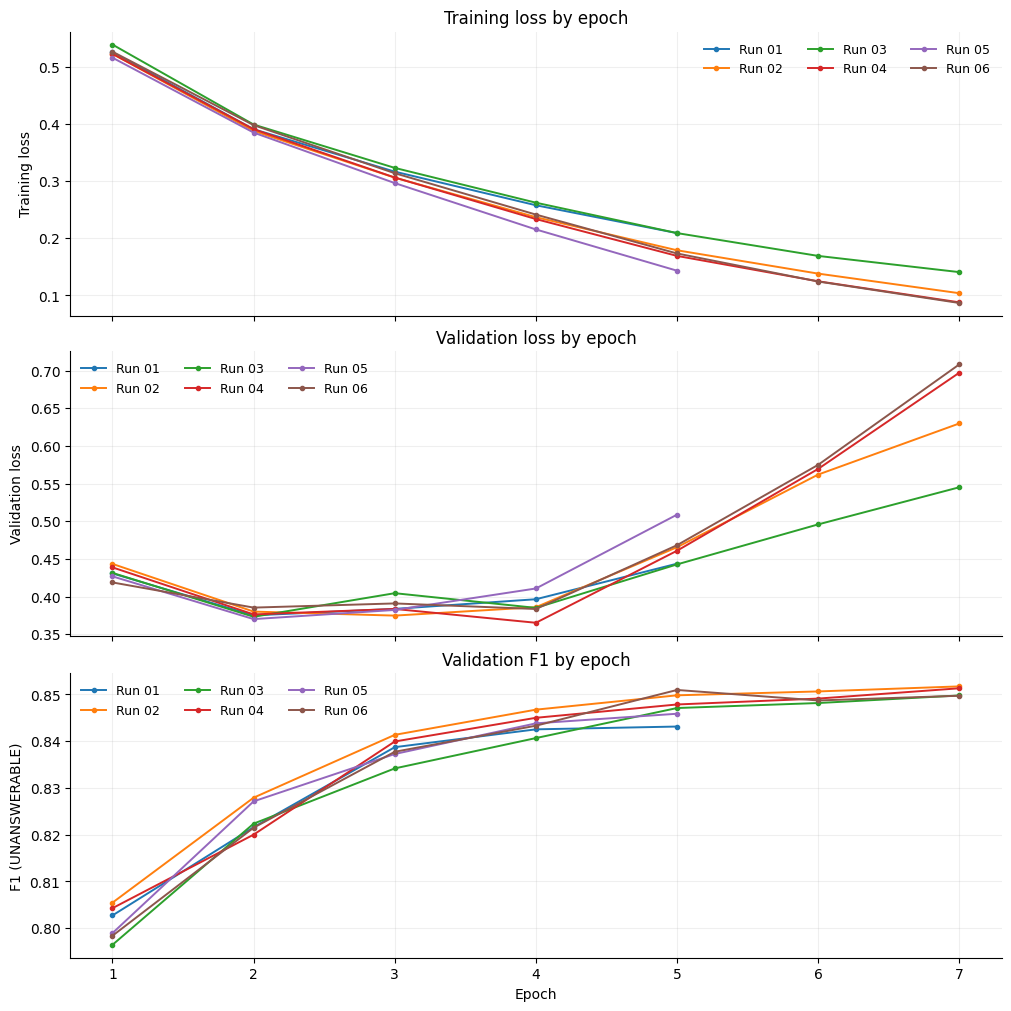

In [4]:
colors = {name: plt.get_cmap("tab10")(i) for i, name in enumerate(runs)}
fig, axes = plt.subplots(3, 1, figsize=(10, 10), sharex=True, layout="constrained")
plot_settings = [
    ("training", "loss", "Training loss", "Training loss by epoch"),
    ("validation", "eval_loss", "Validation loss", "Validation loss by epoch"),
    ("validation", "eval_f1", "F1 (UNANSWERABLE)", "Validation F1 by epoch"),
]
for ax, (event_type, column, ylabel, title) in zip(axes, plot_settings):
    for name, run in runs.items():
        events = run[event_type].sort_values("epoch")
        ax.plot(events["epoch"], events[column], marker="o", markersize=3,
                linewidth=1.4, color=colors[name], label=run_labels[name])
    ax.set(title=title, ylabel=ylabel)
    ax.grid(alpha=0.2)
    ax.legend(ncol=3, frameon=False, fontsize=9)
    ax.set_xticks(sorted({epoch for run in runs.values()
                           for epoch in run["validation"]["epoch"]}))
axes[-1].set_xlabel("Epoch")
plt.show()

In [5]:
selected_events = runs[selected_run]["validation"].sort_values("epoch")
selected_training = runs[selected_run]["training"].sort_values("epoch")
lowest_loss_event = selected_events.loc[selected_events["eval_loss"].idxmin()]
final_event = selected_events.iloc[-1]
display(Markdown(
    f"For {run_labels[selected_run]}, logged training loss decreases from "
    f"{selected_training.iloc[0]['loss']:.4f} to {selected_training.iloc[-1]['loss']:.4f}. "
    f"Validation loss reaches its minimum of {lowest_loss_event['eval_loss']:.4f} "
    f"at epoch {int(lowest_loss_event['epoch'])}, then ends at "
    f"{final_event['eval_loss']:.4f}; validation F1 nevertheless reaches its maximum "
    f"at epoch {int(runs[selected_run]['best']['epoch'])}. Loss and F1 therefore favor "
    "different checkpoints in this run. Run 06 reaches its highest recorded F1 "
    "before the final epoch. These are observations from the logs, not evidence "
    "of a specific causal explanation or a statistical difference between runs."
))

For Run 02, logged training loss decreases from 0.5230 to 0.1038. Validation loss reaches its minimum of 0.3748 at epoch 3, then ends at 0.6299; validation F1 nevertheless reaches its maximum at epoch 7. Loss and F1 therefore favor different checkpoints in this run. Run 06 reaches its highest recorded F1 before the final epoch. These are observations from the logs, not evidence of a specific causal explanation or a statistical difference between runs.

## 5. Model Selection

Run 02 was the validation-selected model used by the existing evaluation script (`src/09_evaluate_bert.py`). Runs 05 and 06 were later exploratory additions testing a higher learning rate with two epoch budgets; all six runs were not specified in advance. The recorded Git sequence places Run 02 test-result commit `89c9fde` before the Run 05/06 script and result commits (`bf04ddb`, `f8d5e2d`). Commit order does not establish exact training timestamps, but these additions must not be presented as completed before the first test evaluation.

The comparison below confirms the validation ranking using all currently available artifacts. Test and UMWP results are not inputs to this calculation.

In [6]:
ranking = sorted(runs, key=lambda name: runs[name]["checkpoint_f1"], reverse=True)
best_name, runner_up = ranking[:2]
margin_pp = 100 * (runs[best_name]["checkpoint_f1"] - runs[runner_up]["checkpoint_f1"])
range_pp = 100 * (max(run["checkpoint_f1"] for run in runs.values())
                  - min(run["checkpoint_f1"] for run in runs.values()))
if selected_run != "run_02":
    raise ValueError("Validation ranking no longer agrees with the recorded Run 02 selection.")
display(Markdown(
    f"**{run_labels[best_name]}** has the highest best-checkpoint validation F1 "
    f"(**{runs[best_name]['checkpoint_f1']:.6f}**) at epoch "
    f"**{int(runs[best_name]['best']['epoch'])}**. Its lead over "
    f"{run_labels[runner_up]} is **{margin_pp:.4f} percentage points**; the full "
    f"six-run range is **{range_pp:.4f} percentage points**. The observed differences "
    "are small in absolute terms. All runs use one recorded seed; no statistical "
    "significance or robustness across seeds is established."
))

**Run 02** has the highest best-checkpoint validation F1 (**0.851733**) at epoch **7**. Its lead over Run 04 is **0.0403 percentage points**; the full six-run range is **0.8596 percentage points**. The observed differences are small in absolute terms. All runs use one recorded seed; no statistical significance or robustness across seeds is established.

## 6. Test Evaluation

Load the recorded frozen Run 02 evaluations from `results/bert/run_02/sum_test/` and `results/bert/run_02/umwp/`. Metrics are read from `metrics.json`; confusion matrices are read from `confusion_matrix.csv` and checked against the JSON. The evaluation script's `calculate_metrics` uses binary UNANSWERABLE precision/recall/F1 and macro-F1 over both labels. No metric is recomputed from predictions here and no model is executed.

,Examples,Accuracy,Precision (UNANSWERABLE),Recall (UNANSWERABLE),F1 (UNANSWERABLE),Macro F1
Dataset,,,,,,
SUM test,10944,0.847953,0.854562,0.838633,0.846523,0.847940
UMWP,5200,0.676154,0.730151,0.558846,0.633115,0.671635


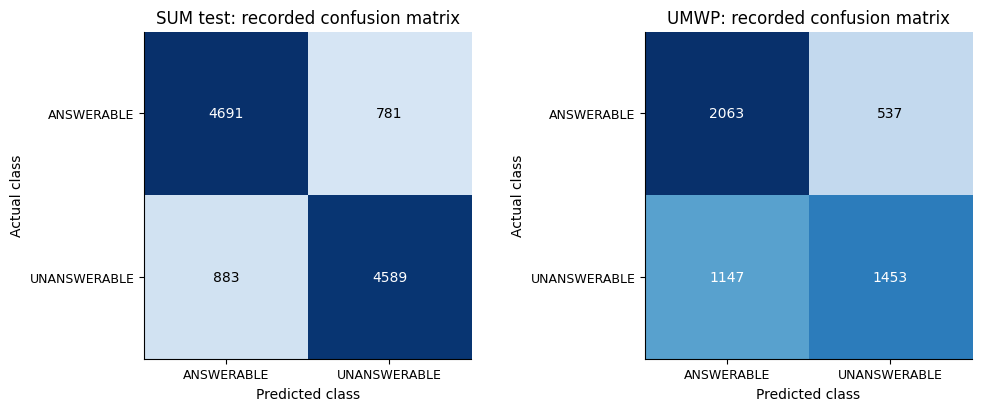

UMWP retains **10** repeated question texts, of which **5** have conflicting labels. The recorded evaluation found **0** duplicate-text groups with inconsistent predictions. Official benchmark rows are preserved; label conflicts limit interpretation of individual errors.

In [7]:
evaluation = {}
confusion_matrices = {}
for folder, dataset_name in [("sum_test", "SUM test"), ("umwp", "UMWP")]:
    directory = BERT_RESULTS / selected_run / folder
    metrics = read_json(directory / "metrics.json")
    if metrics["selected_run"] != selected_run or metrics["positive_class"] != "UNANSWERABLE":
        raise ValueError(f"{folder}: unexpected run or positive class")
    if metrics["confusion_matrix_label_order"] != LABELS:
        raise ValueError(f"{folder}: unexpected confusion-matrix label order")
    matrix = pd.read_csv(directory / "confusion_matrix.csv", index_col=0)
    if list(matrix.index) != LABELS or list(matrix.columns) != LABELS:
        raise ValueError(f"{folder}: confusion-matrix CSV labels differ")
    if matrix.values.tolist() != metrics["confusion_matrix"]:
        raise ValueError(f"{folder}: CSV and JSON confusion matrices disagree")
    if int(matrix.values.sum()) != metrics["total_examples"]:
        raise ValueError(f"{folder}: confusion-matrix total differs from example count")
    evaluation[dataset_name] = metrics
    confusion_matrices[dataset_name] = matrix

test_table = pd.DataFrame([
    {"Dataset": name, "Examples": m["total_examples"], "Accuracy": m["accuracy"],
     "Precision (UNANSWERABLE)": m["precision_unanswerable"],
     "Recall (UNANSWERABLE)": m["recall_unanswerable"],
     "F1 (UNANSWERABLE)": m["f1_unanswerable"], "Macro F1": m["macro_f1"]}
    for name, m in evaluation.items()
]).set_index("Dataset")
display(test_table.style.format({column: "{:.6f}" for column in test_table.columns
                                if column != "Examples"}))

fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
for ax, (name, matrix) in zip(axes, confusion_matrices.items()):
    # Counts use independent color scales because benchmark sizes differ.
    ax.imshow(matrix.values, cmap="Blues", vmin=0, vmax=matrix.values.max())
    for row in range(2):
        for col in range(2):
            count = int(matrix.iloc[row, col])
            ax.text(col, row, str(count), ha="center", va="center",
                    color="white" if count > matrix.values.max() / 2 else "black")
    ax.set_xticks([0, 1], LABELS, fontsize=9)
    ax.set_yticks([0, 1], LABELS, fontsize=9)
    ax.set(title=f"{name}: recorded confusion matrix", xlabel="Predicted class",
           ylabel="Actual class")
plt.show()

duplicates = evaluation["UMWP"]["duplicate_consistency"]
display(Markdown(
    f"UMWP retains **{duplicates['duplicated_question_texts']}** repeated question texts, "
    f"of which **{duplicates['conflicting_ground_truth_texts']}** have conflicting labels. "
    f"The recorded evaluation found **{duplicates['texts_with_inconsistent_predictions']}** "
    "duplicate-text groups with inconsistent predictions. Official benchmark rows are "
    "preserved; label conflicts limit interpretation of individual errors."
))

## 7. Conclusion

In [8]:
sum_metrics = evaluation["SUM test"]
umwp_metrics = evaluation["UMWP"]
f1_gap_pp = 100 * (sum_metrics["f1_unanswerable"] - umwp_metrics["f1_unanswerable"])
recall_gap_pp = 100 * (sum_metrics["recall_unanswerable"] - umwp_metrics["recall_unanswerable"])
display(Markdown(
    f"**{run_labels[selected_run]}** is the selected BERT configuration. On SUM test it "
    f"achieved **{sum_metrics['accuracy']:.2%} accuracy** and "
    f"**{sum_metrics['f1_unanswerable']:.2%} UNANSWERABLE F1**; on external UMWP it "
    f"achieved **{umwp_metrics['accuracy']:.2%} accuracy** and "
    f"**{umwp_metrics['f1_unanswerable']:.2%} UNANSWERABLE F1**. "
    f"The external F1 is **{f1_gap_pp:.2f} percentage points** lower, while UNANSWERABLE "
    f"recall decreases by **{recall_gap_pp:.2f} percentage points**. UMWP includes "
    f"**{confusion_matrices['UMWP'].loc['UNANSWERABLE', 'ANSWERABLE']}** unanswerable "
    "questions classified as answerable. The recorded results show weaker transfer "
    "to UMWP; they do not isolate the cause of the gap."
))

**Run 02** is the selected BERT configuration. On SUM test it achieved **84.80% accuracy** and **84.65% UNANSWERABLE F1**; on external UMWP it achieved **67.62% accuracy** and **63.31% UNANSWERABLE F1**. The external F1 is **21.34 percentage points** lower, while UNANSWERABLE recall decreases by **27.98 percentage points**. UMWP includes **1147** unanswerable questions classified as answerable. The recorded results show weaker transfer to UMWP; they do not isolate the cause of the gap.